# 06 · From evidence to a recommendation

**Owner:** _[name]_ · **Reviewed by:** _[name]_ · **Covers:** spec §3 and §5, brief §8.6 (memo), decisions D1–D9, gaps G1, G2, G4, G26
**Status:** Part A (evidence for the team's decisions) drafted with AI assistance; Part B (the verdict) runs only after the team has locked its inputs.

**Part A** gives the team the evidence to choose each open decision. Not every decision is estimated the same way:

| Kind | Decisions | How a statistician justifies it |
|---|---|---|
| **Preference** (no "true value" in the data) | D1 spending, D2 crisis budget, D8 risk-share cap | Decision analysis: show the consequence of every option, find the **break-even** point where the verdict flips, check the plausible range against it |
| **Uncertain quantity** | D4 equity risk premium, AGG spread | External evidence + data for a range; break-even test of the verdict |
| **Design rule** | D3 caps, D5 shock horizon, D9 monitoring trigger | Fitness for purpose; D9 is **backtested** (designed on 2008–18, confirmed on 2019–22) |
| **Governance** | D6 owners, D7 freeze date | No statistics: the team decides |

**Rules:** explore on data ≤ 2022 only; the team chooses **one central value** (so the verdict is mechanical) **and states the plausible range** with a robustness sentence; values are locked in `doc/decisions/inputs_lock.md` **before** Part B and the final test. Choosing values until the portfolio passes is data snooping and is not allowed.

In [1]:
from pathlib import Path
import hashlib, json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "raw").exists() else Path.cwd()
RAW, ART = ROOT / "data" / "raw", ROOT / "data" / "artifacts"
END = "2022-12-31"                      # test lock: nothing after this date
TICKERS = ["SPY", "EFA", "EEM", "AGG", "GLD", "XLE", "XLK"]
pd.set_option("display.width", 160, "display.precision", 4)

# chart style: validated reference palette, thin marks, recessive grid, text in ink colours
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b86"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.figsize": (9, 4), "figure.dpi": 110,
})

In [2]:
from scipy import optimize
from scipy import stats as st
from sklearn.covariance import LedoitWolf
from arch import arch_model
from matplotlib.colors import to_rgba

raw = pd.read_parquet(RAW / "prices.parquet")
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[raw["date"] <= END]
wide = lambda col: raw.pivot(index="date", columns="ticker", values=col).sort_index()[TICKERS]
adj, close, div = wide("adj_close"), wide("close"), wide("dividends").fillna(0)
R = adj.pct_change(fill_method=None).iloc[1:]

def fred(name):
    s = pd.read_parquet(RAW / f"fred_{name}.parquet").iloc[:, -1]
    s.index = pd.to_datetime(s.index)
    return s.loc[:END].dropna()

EQUITY = ["SPY", "EFA", "EEM", "XLE", "XLK"]
EQ = np.array([t in EQUITY for t in TICKERS], float)
CAPS = {"SPY": .40, "EFA": .40, "EEM": .10, "XLE": .10, "XLK": .10, "GLD": .15, "AGG": .65}   # spec §4; AGG = D3 (provisional)
LEVELS = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
NAV = 10_000_000
rng = np.random.default_rng(20261028)

def min_var_at(x, S):
    res = optimize.minimize(lambda w: w @ S @ w, np.full(7, 1 / 7), method="SLSQP",
                            bounds=[(0.0, CAPS[t]) for t in TICKERS],
                            constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                         {"type": "eq", "fun": lambda w: EQ @ w - x}], options={"ftol": 1e-12})
    assert res.success, res.message
    return np.clip(res.x, 0, None) / np.clip(res.x, 0, None).sum()

S_now = LedoitWolf().fit(R.iloc[-756:].to_numpy()).covariance_ * 252           # optimiser window (as notebook 02)
S_long = LedoitWolf().fit(R.to_numpy()).covariance_ * 252                       # long-run risk for the volatility drag
WEIGHTS = {x: min_var_at(x, S_now) for x in LEVELS}

def path_loss(r):
    v = (1 + r).cumprod(); return float(-(v / np.maximum(v.cummax(), 1.0) - 1).min())
CRISES = {"GFC 2008": ("2007-10-09", "2009-03-09"), "COVID 2020": ("2020-02-19", "2020-03-23"), "Rate shock 2022": ("2022-01-03", "2022-10-12")}
def crisis_loss(w):
    return max(path_loss(R.loc[(R.index > a) & (R.index <= b)] @ w) for a, b in CRISES.values())
CRISIS = {x: crisis_loss(wx) for x, wx in WEIGHTS.items()}
print("worst historical crisis loss with today's weights:", {f"{x:.0%}": f"{v:.1%}" for x, v in CRISIS.items()})

worst historical crisis loss with today's weights: {'20%': '18.2%', '25%': '20.2%', '30%': '22.4%', '35%': '24.4%', '40%': '26.6%', '45%': '29.0%', '50%': '31.9%'}


## A1 · D4: the equity risk premium and the AGG spread (uncertain quantities)

Forward-looking expected returns (spec §3.1) need two inputs no one can observe exactly. Evidence:
1. **Our data:** the realised premium of SPY over T-bills and of AGG over a Treasury proxy, 2004–2022. One sample period is weak evidence (it depends on where it starts and ends), so it only frames the range.
2. **Outside evidence:** academic and practitioner estimates put the forward US equity premium roughly in a **3–6%** band. The owner must cite the specific sources used (for example long-run historical premia and implied-ERP estimates).

The verdict's sensitivity to the ERP is tested by its **break-even** value in A3.

In [3]:
rf_d = ((1 + 365 * (fred("DTB3").reindex(R.index, method="ffill") / 100) /
         (360 - 91 * fred("DTB3").reindex(R.index, method="ffill") / 100)) ** (1 / 252) - 1).shift(1).bfill()
years = len(R) / 252
spy_x = float((1 + R["SPY"]).prod() ** (1 / years) - (1 + rf_d).prod() ** (1 / years))
# Treasury proxy with AGG-like duration (about 6): yield of a 2/10-year blend, carry plus duration effect
y_mid = (fred("DGS2") + fred("DGS10")).reindex(R.index, method="ffill") / 200
tsy = y_mid.shift(1) / 252 - 6.0 * y_mid.diff()
agg_x = float((1 + R["AGG"]).prod() ** (1 / years) - (1 + tsy.fillna(0)).prod() ** (1 / years))
print(f"realised 2004-22: SPY over T-bills {spy_x:+.2%} a year; AGG over a duration-6 Treasury proxy {agg_x:+.2%} a year")
print(f"end-2022 market levels: 10-year yield {fred('DGS10').iloc[-1]:.2f}%, 2-year {fred('DGS2').iloc[-1]:.2f}%, "
      f"10-year breakeven inflation {fred('T10YIE').iloc[-1]:.2f}%, real yield {fred('DFII10').iloc[-1]:.2f}%")

realised 2004-22: SPY over T-bills +7.55% a year; AGG over a duration-6 Treasury proxy +0.90% a year
end-2022 market levels: 10-year yield 3.88%, 2-year 4.41%, 10-year breakeven inflation 2.30%, real yield 1.58%


**Evidence:**
- **ERP.** In our sample SPY beat T-bills by 7.6% a year, above the usual 3–6% band, because 2004–22 was an exceptional period for US stocks (valuations rose). It frames the top of the range; it is not a forecast.
- **AGG spread.** AGG beat a duration-6 Treasury proxy by about 0.9% a year (a crude proxy that also picks up its mortgage and corporate premia), so a 0.5% central spread is on the cautious side; the plausible range is 0.3–0.9%.
- **Market levels at end-2022:** 10-year yield 3.88%, 2-year 4.41% (an inverted curve, during a hiking cycle), breakeven inflation 2.30%.
- **Definition matters.** Our ERP is **arithmetic**, and we subtract the volatility drag σ²/2. A geometric ERP would add about 0.3 pp at 35% equity (immaterial) but about 2 pp for 100% equity.

**Agreed D4 (2026-10-28):** ERP **4.5%** (arithmetic; range 3.5–5.5%), AGG spread 0.5% (range 0.3–0.9%), stated as a **disclosed assumption**: anchored on this approved data and only cross-checked against published estimates (booklet p. 9: no undisclosed or proprietary data sources). A3 shows how much the verdict depends on it.

## A2 · D1 and D2 together: the decision map

Spending (D1) sets how much return the fund needs; the crisis budget (D2) sets how much equity it may hold. They must be chosen **together**, because one trades against the other.

For every frontier point we compute the **net forward expected return** (spec §3.1: AGG = 10-year yield + spread; equities = 10-year yield + β × ERP; gold = breakeven inflation; minus expense ratios and US withholding tax on equity dividends; minus the volatility drag σ²/2), and its **worst historical crisis loss** with today's weights. The required return is (1 + spending)(1 + breakeven inflation) − 1.

Verdict for each (spending, budget) pair, by the spec §5 rule: **ACCEPT** if some point meets the required return within the budget (recommend the lowest-risk one); **ADJUST** if one does with the budget loosened by at most 5 pp; otherwise **REJECT**.

**Cost assumptions** (to verify on the issuers' pages; used as costs, not as data): expense ratios SPY 0.09%, EFA 0.33%, EEM 0.70%, AGG 0.03%, GLD 0.40%, XLE 0.09%, XLK 0.09%; trading about 0.01% a year; 15% withholding on equity dividends; AGG assumed exempt (sensitivity in A3).

breakeven inflation 2.30%; required return at the agreed 3% spending + 0.5% growth: 5.90%


,net forward return,worst crisis loss
20%,4.32%,18.17%
25%,4.54%,20.24%
30%,4.75%,22.36%
35%,4.91%,24.41%
40%,4.99%,26.59%
45%,5.04%,29.00%
50%,5.07%,31.88%


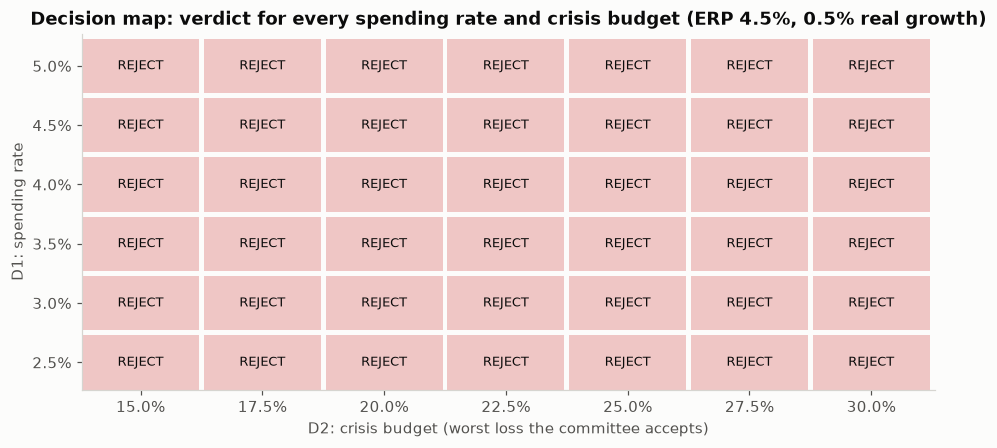

In [4]:
ERP_C, SPREAD_C, GROWTH = 0.045, 0.005, 0.005                        # agreed D4 (ERP, AGG spread) and the real-growth margin (D1)
EXPENSE = pd.Series({"SPY": .000945, "EFA": .0033, "EEM": .0070, "AGG": .0003, "GLD": .0040, "XLE": .0009, "XLK": .0009})
y10, pi = fred("DGS10").iloc[-1] / 100, fred("T10YIE").iloc[-1] / 100
est = R.iloc[-756:]
beta = (est.cov()["SPY"] / est["SPY"].var()).reindex(TICKERS)
div_yield = (div.loc[R.index[-1] - pd.Timedelta(days=365):].sum() / close.iloc[-1]).reindex(TICKERS)
WHT = pd.Series({t: 0.15 if t in EQUITY else 0.0 for t in TICKERS})

def expected_return(w, erp=ERP_C, spread=SPREAD_C, agg_wht=0.0, dy=0.0):
    """Net geometric forward return; dy shifts the 10-year yield with inflation unchanged (a real-yield scenario)."""
    y = y10 + dy
    mu = pd.Series({t: (y + spread if t == "AGG" else pi if t == "GLD" else y + beta[t] * erp) for t in TICKERS})
    wht = WHT.copy(); wht["AGG"] = agg_wht
    net = mu - EXPENSE.reindex(TICKERS) - div_yield * wht - 0.0001
    return float(w @ net.to_numpy() - 0.5 * w @ S_long @ w)      # geometric (compound) return

def required(s):
    return (1 + s) * (1 + GROWTH) * (1 + pi) - 1          # spending + real growth + inflation (objective: CPI + s + 0.5%)

def verdict(s, dmax, erp=ERP_C, spread=SPREAD_C, agg_wht=0.0, dy=0.0):
    er = lambda x: expected_return(WEIGHTS[x], erp, spread, agg_wht, dy)
    ok = [x for x in LEVELS if CRISIS[x] <= dmax + 1e-9 and er(x) >= required(s)]
    if ok:
        return "ACCEPT", min(ok)
    near = [x for x in LEVELS if CRISIS[x] <= dmax + 0.05 + 1e-9 and er(x) >= required(s)]
    return ("ADJUST", min(near)) if near else ("REJECT", None)

fwd = pd.DataFrame({"net forward return": {f"{x:.0%}": expected_return(WEIGHTS[x]) for x in LEVELS},
                    "worst crisis loss": {f"{x:.0%}": CRISIS[x] for x in LEVELS}})
print(f"breakeven inflation {pi:.2%}; required return at the agreed 3% spending + 0.5% growth: {required(0.03):.2%}")
display(fwd.style.format("{:.2%}"))

SPEND = [0.025, 0.030, 0.035, 0.040, 0.045, 0.050]
DMAX = [0.150, 0.175, 0.200, 0.225, 0.250, 0.275, 0.300]
grid = {(s, d): verdict(s, d) for s in SPEND for d in DMAX}
COLOR = {"ACCEPT": "#0ca30c", "ADJUST": "#fab219", "REJECT": "#d03b3b"}
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, s in enumerate(SPEND):
    for j, d in enumerate(DMAX):
        v, x = grid[(s, d)]
        ax.add_patch(plt.Rectangle((j, i), 0.96, 0.92, color=to_rgba(COLOR[v], 0.28), linewidth=0))
        ax.text(j + 0.48, i + 0.46, v + ("" if x is None else f"\n{x:.0%} equity"), ha="center", va="center", fontsize=8.5, color=INK)
ax.set(xlim=(0, len(DMAX)), ylim=(0, len(SPEND)), xlabel="D2: crisis budget (worst loss the committee accepts)",
       ylabel="D1: spending rate", title="Decision map: verdict for every spending rate and crisis budget (ERP 4.5%, 0.5% real growth)")
ax.set_xticks(np.arange(len(DMAX)) + 0.48, [f"{d:.1%}" for d in DMAX]); ax.set_yticks(np.arange(len(SPEND)) + 0.46, [f"{s:.1%}" for s in SPEND])
ax.grid(False)
plt.show()

**Evidence:** at end-2022 market levels the agreed objective (3% spending + 0.5% real growth + inflation = **5.9%** required) is **not** met within any plausible crisis budget: the net forward return runs from 4.3% (20% equity) to 5.1% (50% equity). Budgets of 15% and 17.5% have no feasible point at all (the caps force at least 20% equity, which lost 18.2% in the GFC). On end-2022 levels the binding problem is the market's low real yield, not the risk budget.

### A2b · The more useful question: what spending can each crisis budget sustainably fund?

Turn the question around: for each crisis budget and ERP, take the best feasible point (the highest net forward return whose worst crisis loss fits the budget) and compute the spending rate it can fund while still growing 0.5% a year in real terms: (1 + return) / ((1 + inflation)(1 + 0.5%)) − 1. Two reference portfolios **outside the IPS** (60/40 SPY/AGG and 100% SPY) show what it would take.

,ERP 3.5%,ERP 4.5%,ERP 5.5%,equity share used (ERP 4.5%)
15.0%,none feasible,none feasible,none feasible,nan%
17.5%,none feasible,none feasible,none feasible,nan%
20.0%,1.29%,1.47%,1.64%,20%
22.5%,1.63%,1.88%,2.14%,30%
25.0%,1.75%,2.05%,2.34%,35%
27.5%,1.78%,2.12%,2.46%,40%
30.0%,1.78%,2.16%,2.54%,45%


,"sustainable spending, ERP 3.5%","sustainable spending, ERP 4.5%","sustainable spending, ERP 5.5%",worst crisis loss
60/40 SPY/AGG,2.37%,2.95%,3.54%,34.70%
100% SPY,2.24%,3.21%,4.18%,55.19%


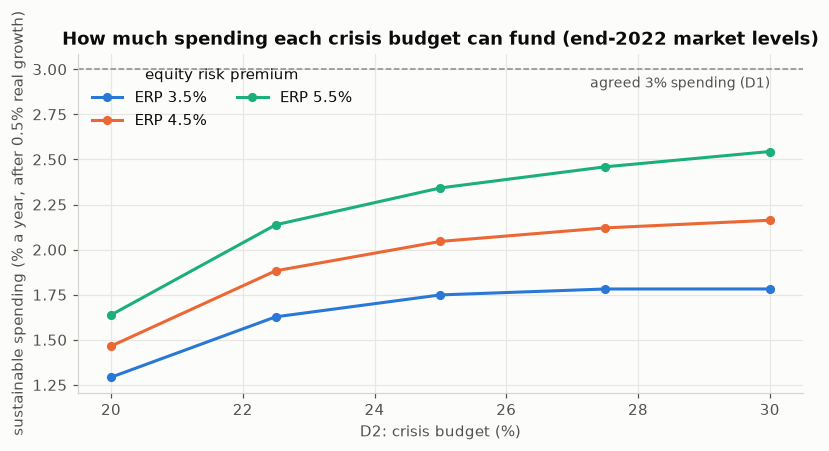

In [5]:
def best_feasible(dmax, erp):
    feas = [x for x in LEVELS if CRISIS[x] <= dmax + 1e-9]
    if not feas:
        return None, np.nan
    x = max(feas, key=lambda v: expected_return(WEIGHTS[v], erp))
    return x, (1 + expected_return(WEIGHTS[x], erp)) / ((1 + pi) * (1 + GROWTH)) - 1
ERPS = [0.035, 0.045, 0.055]
sust = pd.DataFrame({f"ERP {e:.1%}": {f"{d:.1%}": best_feasible(d, e)[1] for d in DMAX} for e in ERPS})
used = pd.Series({f"{d:.1%}": best_feasible(d, ERP_C)[0] for d in DMAX}, name="equity share used (ERP 4.5%)")
display(pd.concat([sust, used.map(lambda v: "none feasible" if v is None else f"{v:.0%}")], axis=1)
        .style.format({c: "{:.2%}" for c in sust.columns}, na_rep="none feasible"))
ref_w = {"60/40 SPY/AGG": np.array([.6 if t == "SPY" else .4 if t == "AGG" else 0 for t in TICKERS]),
         "100% SPY": np.array([1.0 if t == "SPY" else 0 for t in TICKERS])}
ref = pd.DataFrame({k: {**{f"sustainable spending, ERP {e:.1%}": (1 + expected_return(wv, e)) / ((1 + pi) * (1 + GROWTH)) - 1 for e in ERPS},
                        "worst crisis loss": crisis_loss(wv)} for k, wv in ref_w.items()}).T
display(ref.style.format("{:.2%}").set_caption("Reference portfolios outside the IPS"))
fig, ax = plt.subplots(figsize=(8.5, 4))
for e, colr in zip(ERPS, [BLUE, ORANGE, AQUA]):
    ax.plot([d * 100 for d in DMAX], sust[f"ERP {e:.1%}"] * 100, color=colr, marker="o", markersize=5, label=f"ERP {e:.1%}")
ax.axhline(3.0, color=GREY, linestyle="--", linewidth=1)
ax.text(DMAX[-1] * 100, 2.96, "agreed 3% spending (D1)", color=INK2, fontsize=9, ha="right", va="top")
ax.set(xlabel="D2: crisis budget (%)", ylabel="sustainable spending (% a year, after 0.5% real growth)",
       title="How much spending each crisis budget can fund (end-2022 market levels)")
ax.legend(loc="upper left", title="equity risk premium", ncol=2)
plt.show()

**Evidence:**
- **At end-2022 levels, a 25% crisis budget funds about 2.0% spending** while still growing 0.5% a year in real terms (1.75–2.34% for ERP 3.5–5.5%).
- The curve flattens above 25%: more crisis budget buys little extra capacity, because equity is capped at 50% and extra equity adds little net return after costs and drag.
- Even outside the IPS, 60/40 funds about 2.95% (with a 35% crisis loss) and 100% SPY 3.2% (with a 55% loss).

The committee's choice is therefore driven far more by the **market's real yield** than by the risk budget (A2c).

## A3 · How robust is the verdict? Break-even values

For each spending rate, the **break-even ERP** is the lowest equity risk premium at which an acceptable point exists within a 25% crisis budget. If the plausible ERP range (3–6%) lies above it, the verdict is robust to D4. We repeat it with a lower AGG spread and with AGG taxed.

In [6]:
def breakeven_erp(s, dmax=0.25, spread=SPREAD_C, agg_wht=0.0):
    for erp in np.arange(0.0, 0.1001, 0.0005):
        if verdict(s, dmax, erp, spread, agg_wht)[0] == "ACCEPT":
            return erp
    return np.nan
rows = []
for s in SPEND:
    rows.append({"spending": f"{s:.1%}", "required return": required(s),
                 "break-even ERP (central)": breakeven_erp(s),
                 "with AGG spread 0.3%": breakeven_erp(s, spread=0.003),
                 "with AGG taxed 15%": breakeven_erp(s, agg_wht=0.15),
                 "verdict at ERP 3.5% / 4.5% / 5.5%": " / ".join(f"{verdict(s, 0.25, e)[0]}" for e in (0.035, 0.045, 0.055))})
pd.DataFrame(rows).set_index("spending").style.format({c: "{:.2%}" for c in ["required return", "break-even ERP (central)",
                                                                             "with AGG spread 0.3%", "with AGG taxed 15%"]}, na_rep="none ≤ 10%")

,required return,break-even ERP (central),with AGG spread 0.3%,with AGG taxed 15%,verdict at ERP 3.5% / 4.5% / 5.5%
spending,,,,,
2.5%,5.38%,6.05%,6.50%,6.80%,REJECT / REJECT / ADJUST
3.0%,5.90%,7.75%,8.15%,8.50%,REJECT / REJECT / REJECT
3.5%,6.41%,9.45%,9.85%,none ≤ 10%,REJECT / REJECT / REJECT
4.0%,6.92%,none ≤ 10%,none ≤ 10%,none ≤ 10%,REJECT / REJECT / REJECT
4.5%,7.44%,none ≤ 10%,none ≤ 10%,none ≤ 10%,REJECT / REJECT / REJECT
5.0%,7.95%,none ≤ 10%,none ≤ 10%,none ≤ 10%,REJECT / REJECT / REJECT


**Evidence:** at end-2022 levels, 3% spending would need an ERP of **7.75%**, far above any plausible value; 2.5% spending needs about 6%. So at those levels the verdict "not achievable" is robust to D4, the AGG spread and the tax treatment. What moves it is the yield level (A2c).

## A2c · What if real yields are higher at the decision date?

The dry run uses end-2022 market levels. The decision date is later, and the test lock forbids reading 2023+ data before the freeze, so instead of looking we **shift the 10-year yield** by +0.5, +1.0 and +1.5 pp with inflation unchanged (a real-yield scenario). This shows how much the conclusion depends on the market level at the decision date; the real figure is computed after the freeze.

In [7]:
rows = []
for dy in [0.0, 0.005, 0.010, 0.015]:
    for e in [0.035, 0.045, 0.055]:
        feas = [x for x in LEVELS if CRISIS[x] <= 0.25 + 1e-9]
        best = max(feas, key=lambda v: expected_return(WEIGHTS[v], e, dy=dy))
        cap = (1 + expected_return(WEIGHTS[best], e, dy=dy)) / ((1 + pi) * (1 + GROWTH)) - 1
        v, x = verdict(0.03, 0.25, e, dy=dy)
        rows.append({"real yield shift": f"+{dy:.1%}", "ERP": f"{e:.1%}", "sustainable spending (25% budget)": cap,
                     "verdict for 3% spending": v + ("" if x is None else f" at {x:.0%} equity")})
ry = pd.DataFrame(rows)
display(ry.pivot(index="real yield shift", columns="ERP", values="sustainable spending (25% budget)").style.format("{:.2%}"))
ry.pivot(index="real yield shift", columns="ERP", values="verdict for 3% spending")

ERP,3.5%,4.5%,5.5%
real yield shift,,,
+0.0%,1.75%,2.05%,2.34%
+0.5%,2.23%,2.53%,2.82%
+1.0%,2.71%,3.01%,3.31%
+1.5%,3.20%,3.49%,3.79%


ERP,3.5%,4.5%,5.5%
real yield shift,,,
+0.0%,REJECT,REJECT,REJECT
+0.5%,REJECT,REJECT,ADJUST at 45% equity
+1.0%,REJECT,ACCEPT at 35% equity,ACCEPT at 30% equity
+1.5%,ACCEPT at 30% equity,ACCEPT at 30% equity,ACCEPT at 25% equity


**Evidence:**
- **The verdict depends on the real yield at the decision date.** At end-2022 levels the agreed 3% spending fails for every plausible ERP.
- With the 10-year real yield **1 pp higher** (inflation unchanged), the 25% budget funds about **3.0% spending with 0.5% growth at ERP 4.5%**, and the verdict becomes **ACCEPT at 35% equity**.
- At +1.5 pp it is ACCEPT for every ERP in the range; at +0.5 pp it is still REJECT (or ADJUST at the top ERP).

**What it means:** D1 = 3% sits right at the break-even of a +1 pp real-yield move. If the decision-date real yield is at least about 1 pp above end-2022 (2.6% or more on the 10-year TIPS yield), the mandate is ACCEPT with the agreed objective; if not, D10's fallback applies (ADJUST THE RISK LIMIT, with the dollar cost). This is computed after the freeze from the locked inputs; nothing here uses 2023+ data.

## A4 · D1 in the long run: will the fund keep its purchasing power? (context, not a verdict criterion)

Ten years of monthly returns are resampled from 2005–2022 together with US inflation (stationary bootstrap, mean block 12 months, so crises and recoveries stay together), with each portfolio's mean re-centred to its forward estimate. Spending is the rate × the average value of the previous 36 months, paid monthly. We report the probability that the **real** value (after inflation and spending) ends below 80% of today's.

In [8]:
cpi = fred("CPIAUCSL")
monthly = (1 + R.loc["2005-01-01":]).resample("ME").prod() - 1
infl_m = cpi.pct_change().reindex(monthly.index, method="ffill").to_numpy()

def simulate(x, s, block=12, paths=5000, months=120):
    r = (monthly @ WEIGHTS[x]).to_numpy()
    target = (1 + expected_return(WEIGHTS[x])) ** (1 / 12) - 1
    r = r - r.mean() + target                                         # re-centre to the forward estimate
    f = infl_m - infl_m.mean() + ((1 + pi) ** (1 / 12) - 1)            # inflation re-centred to the breakeven
    n = len(r)
    idx = rng.integers(0, n, paths)
    value, price, hist = np.ones(paths), np.ones(paths), [np.ones(paths)] * 36
    for _ in range(months):
        value = value * (1 + r[idx]); price = price * (1 + f[idx])
        hist = hist[1:] + [value]
        value = value - s / 12 * np.mean(hist, axis=0)
        jump = rng.random(paths) < 1 / block
        idx = np.where(jump, rng.integers(0, n, paths), (idx + 1) % n)
    real = value / price
    return float(np.mean(real < 0.8)), float(np.median(real)), float(np.sqrt(np.mean(real < 0.8) * (1 - np.mean(real < 0.8)) / paths))

rows = []
for x in [0.20, 0.35, 0.50]:
    for s in [0.030, 0.035, 0.040]:
        p, med, se = simulate(x, s)
        rows.append({"equity": f"{x:.0%}", "spending": f"{s:.1%}", "P(real value < 80%)": p, "Monte Carlo s.e.": se, "median real value": med})
sim = pd.DataFrame(rows)
blocks = {f"block {b} months": simulate(0.35, 0.03, block=b)[0] for b in (1, 12, 36)}
display(sim.pivot(index="equity", columns="spending", values="P(real value < 80%)").style.format("{:.1%}"))
display(sim.pivot(index="equity", columns="spending", values="median real value").style.format("{:.2f}"))
print("block-length sensitivity, 35% equity at 3% spending:", {k: f"{v:.1%}" for k, v in blocks.items()})

spending,3.0%,3.5%,4.0%
equity,,,
20%,31.1%,38.4%,47.3%
35%,25.8%,30.7%,40.0%
50%,28.6%,34.6%,41.8%


spending,3.0%,3.5%,4.0%
equity,,,
20%,0.90,0.86,0.81
35%,0.95,0.91,0.85
50%,0.95,0.90,0.85


block-length sensitivity, 35% equity at 3% spending: {'block 1 months': '25.6%', 'block 12 months': '25.2%', 'block 36 months': '20.2%'}


**Evidence:** even at end-2022 levels (the cautious case), 3% spending at 35% equity gives about a **26% chance that real value ends below 80% within 10 years**, with a median real value of 0.95. That compares with about 40% at 4% spending (median 0.85). The block-length sensitivity is 20–26%, Monte Carlo standard error about 0.6 pp. Cutting spending from 4% to 3% roughly halves the risk of a large loss of purchasing power, and that is in the low-yield case.
**The committee sentence:** “At 3% spending the fund keeps most of its purchasing power in most scenarios; at 4% it has close to an even chance of losing a fifth of it within ten years.”

## A5 · D5: over what horizon should the hypothetical shock be applied?

The hypothetical stagflation scenario needs a horizon: a one-day shock, a month or a quarter. The evidence is how past crises actually unfolded for today's 35% portfolio: how much of each crisis loss came within the worst day, month and quarter.

In [9]:
w35 = WEIGHTS[0.35]
rows = []
for name, (a, b) in CRISES.items():
    r = R.loc[(R.index > a) & (R.index <= b)] @ w35
    lv = np.log1p(r)
    worst = {h: float(-np.expm1(lv.rolling(h).sum().min())) if len(lv) >= h else np.nan for h in (1, 21, 63)}
    total = path_loss(r)
    rows.append({"crisis": name, "trading days": len(r), "total loss": total, "worst day": worst[1],
                 "worst month (21d)": worst[21], "worst quarter (63d)": worst[63],
                 "share of total in worst quarter": worst[63] / total if np.isfinite(worst[63]) else np.nan})
pd.DataFrame(rows).set_index("crisis").style.format({c: "{:.1%}" for c in ["total loss", "worst day", "worst month (21d)",
                                                                           "worst quarter (63d)", "share of total in worst quarter"]}, na_rep="n/a")

,trading days,total loss,worst day,worst month (21d),worst quarter (63d),share of total in worst quarter
crisis,,,,,,
GFC 2008,355,24.4%,5.3%,18.1%,19.9%,81.4%
COVID 2020,23,15.5%,6.3%,14.0%,n/a,n/a
Rate shock 2022,195,18.8%,2.3%,8.2%,9.9%,52.4%


**Evidence:** crises unfold at very different speeds. The GFC delivered 81% of its loss within its worst quarter; COVID lost 15.5% in 23 trading days; the 2022 rate shock was a slow grind, with only 52% of its loss within any single quarter over 9 months. A one-day shock would understate a 2022-type stagflation, and a one-quarter shock captures only half of it.
**Proposed D5:** apply the hypothetical stagflation shock as a **cumulative peak-to-trough episode** of about three quarters, modelled on 2022. That makes it directly comparable with D_max, which is also peak-to-trough, and the worst quarter is shown separately as the speed.

## A6 · D8: how much of the tail risk may one ETF carry?

Euler 99% ES shares (full 2004–2022 history, today's weights) for every frontier point. A cap is useful only if it is reachable and changes something.

In [10]:
rows = {}
for x, wx in WEIGHTS.items():
    l = -(R @ wx); tail = l >= l.quantile(0.99)
    share = pd.Series(wx * (-R.loc[tail].mean().to_numpy()), index=TICKERS) / l[tail].mean()
    rows[f"{x:.0%}"] = share
shares = pd.DataFrame(rows).T
shares["largest share"] = shares[TICKERS].max(axis=1)
shares["held by"] = shares[TICKERS].idxmax(axis=1)
for cap in (0.35, 0.40, 0.50):
    shares[f"meets {cap:.0%} cap"] = np.where(shares["largest share"] <= cap, "yes", "no")
shares.style.format({**{t: "{:.0%}" for t in TICKERS}, "largest share": "{:.0%}"})

,SPY,EFA,EEM,AGG,GLD,XLE,XLK,largest share,held by,meets 35% cap,meets 40% cap,meets 50% cap
20%,17%,26%,15%,27%,15%,0%,0%,27%,AGG,yes,yes,yes
25%,18%,36%,18%,21%,6%,0%,0%,36%,EFA,no,yes,yes
30%,18%,43%,20%,18%,1%,0%,0%,43%,EFA,no,no,yes
35%,18%,47%,22%,14%,0%,0%,0%,47%,EFA,no,no,yes
40%,18%,50%,22%,10%,0%,0%,0%,50%,EFA,no,no,no
45%,18%,53%,22%,7%,-0%,0%,0%,53%,EFA,no,no,no
50%,18%,54%,22%,5%,0%,0%,0%,54%,EFA,no,no,no


**Evidence:** with minimum-variance weights, EFA's share of the tail risk passes 40% from 30% equity and 50% from 40% equity. A **40% cap** binds exactly in the 30–35% range where the recommendation is likely to sit, so it forces a real resizing (towards SPY). A 35% cap would already bind at 25% equity; a 50% cap would barely ever bind.
**Proposed D8:** 40%. The resizing itself happens in Part B.

## A7 · D9: does a monitoring trigger actually protect the fund? (backtest)

Proposed rule: when the 1-day 99% ES **forecast** stays above the ES limit for N trading days in a row, move from the 35% point to the 20% point; move back when it stays below for N days. The forecast comes from a GJR-GARCH-t fitted on **2004–2018 only** (notebook 03 §5 found it passes the residual checks), then run forward without refitting, so 2019–2022 is genuinely out of sample. N is **designed on 2008–2018** and **confirmed on 2019–2022**. Switching costs 5 bp per side.

In [11]:
w20 = WEIGHTS[0.20]
p35, p20 = R @ w35, R @ w20
dev_end = "2018-12-31"
am = arch_model(p35 * 100, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t")
fit_dev = am.fit(last_obs=dev_end, disp="off")
sig = am.fix(fit_dev.params).conditional_volatility / 100            # sigma_t uses information up to t-1
nu, mu_ = fit_dev.params["nu"], fit_dev.params["mu"] / 100
q = st.t.ppf(0.99, nu)
es_std = st.t.pdf(q, nu) / 0.01 * (nu + q**2) / (nu - 1) * np.sqrt((nu - 2) / nu)
es_fc = -mu_ + sig * es_std
dev_l = -(R.loc[:dev_end] @ w35)
LIMIT = float(np.interp(0.25, [CRISIS[x] for x in LEVELS], [(-(R.loc[:dev_end] @ WEIGHTS[x])).pipe(lambda l: l[l >= l.quantile(0.99)].mean()) for x in LEVELS]))
print(f"ES limit used (through-the-cycle, D_max 25%): {LIMIT:.2%}; days the forecast exceeds it 2008-22: {(es_fc.loc['2008':] > LIMIT).mean():.1%}")

turn = float(np.abs(w35 - w20).sum())
def run_trigger(n, start, end):
    over = (es_fc > LIMIT).astype(int)
    state, on_run, off_run, out, switches, spells = 1, 0, 0, [], 0, []
    dates = R.loc[start:end].index
    for t in dates:
        o = over.loc[t]
        on_run = on_run + 1 if o else 0; off_run = off_run + 1 if not o else 0
        ret = p35.loc[t] if state == 1 else p20.loc[t]
        if state == 1 and on_run >= n:
            state, switches = 0, switches + 1; ret -= 5e-4 * turn; spells.append([t, None])
        elif state == 0 and off_run >= n:
            state, switches = 1, switches + 1; ret -= 5e-4 * turn; spells[-1][1] = t
        out.append(ret)
    trig = pd.Series(out, index=dates); static = p35.loc[dates]
    false = sum(1 for a, b in spells if path_loss(static.loc[a:b if b is not None else dates[-1]]) < 0.03)
    yrs = len(dates) / 252
    return {"switches / year": switches / yrs, "risk-off spells": len(spells), "false alarms (< 3% loss avoided)": false,
            "max drawdown, static": -path_loss(static), "max drawdown, trigger": -path_loss(trig),
            "return / year, static": float((1 + static).prod() ** (1 / yrs) - 1), "return / year, trigger": float((1 + trig).prod() ** (1 / yrs) - 1)}, trig

design = pd.DataFrame({n: run_trigger(n, "2008-01-01", dev_end)[0] for n in (1, 5, 10, 20)}).T
confirm = pd.DataFrame({n: run_trigger(n, "2019-01-01", END)[0] for n in (1, 5, 10, 20)}).T
fmt = {c: "{:.1%}" for c in design.columns if "drawdown" in c or "return" in c}
display(design.rename_axis("N days").style.format({**fmt, "switches / year": "{:.1f}"}).set_caption("Design period 2008–2018"))
display(confirm.rename_axis("N days").style.format({**fmt, "switches / year": "{:.1f}"}).set_caption("Confirmation period 2019–2022 (out of sample)"))

ES limit used (through-the-cycle, D_max 25%): 2.22%; days the forecast exceeds it 2008-22: 8.7%


,switches / year,risk-off spells,false alarms (< 3% loss avoided),"max drawdown, static","max drawdown, trigger","return / year, static","return / year, trigger"
N days,,,,,,,
1,2.9,16.000000,14.000000,-24.4%,-20.0%,3.8%,4.0%
5,0.7,4.000000,2.000000,-24.4%,-21.2%,3.8%,4.2%
10,0.4,2.000000,0.000000,-24.4%,-22.6%,3.8%,3.7%
20,0.4,2.000000,0.000000,-24.4%,-24.4%,3.8%,3.8%


,switches / year,risk-off spells,false alarms (< 3% loss avoided),"max drawdown, static","max drawdown, trigger","return / year, static","return / year, trigger"
N days,,,,,,,
1,3.5,7.000000,5.000000,-20.3%,-21.6%,2.8%,2.7%
5,2.0,4.000000,2.000000,-20.3%,-21.0%,2.8%,2.3%
10,1.5,3.000000,2.000000,-20.3%,-20.9%,2.8%,2.0%
20,1.0,2.000000,2.000000,-20.3%,-20.8%,2.8%,2.0%


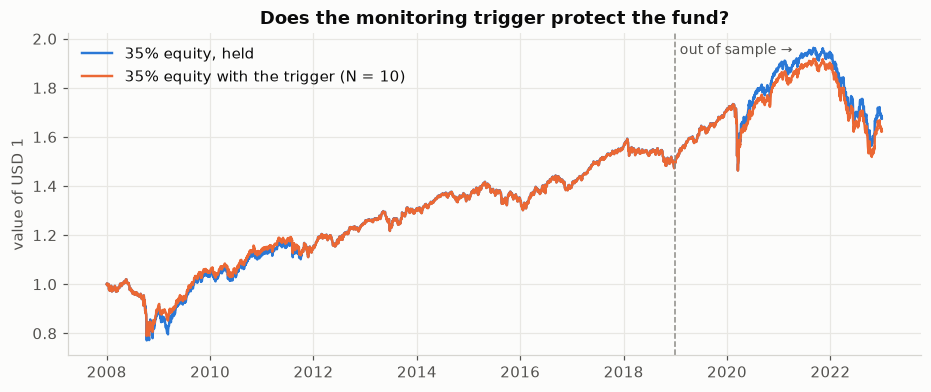

In [12]:
N_PICK = 10                                                          # provisional; the owner confirms from the design table
_, trig = run_trigger(N_PICK, "2008-01-01", END)
static = p35.loc[trig.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(static.index, (1 + static).cumprod(), color=BLUE, linewidth=1.6, label="35% equity, held")
ax.plot(trig.index, (1 + trig).cumprod(), color=ORANGE, linewidth=1.6, label=f"35% equity with the trigger (N = {N_PICK})")
ax.axvline(pd.Timestamp("2019-01-01"), color=GREY, linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2019-02-01"), ax.get_ylim()[1] * 0.98, "out of sample →", color=INK2, fontsize=9, va="top")
ax.set(ylabel="value of USD 1", title="Does the monitoring trigger protect the fund?")
ax.legend(loc="upper left")
plt.show()

**Evidence:**
- **In the design period the rule looked useful.** With N = 5 days the worst loss fell from 24.4% to 21.2%, return rose 0.4 pp a year, and there were 2 false alarms out of 4 spells. With N = 10 there were no false alarms but little protection.
- **Out of sample (2019–22) every version made things worse:** a deeper worst loss (20.8–21.6% vs 20.3%) and lower return (2.0–2.7% vs 2.8%). The COVID crash was over before the rule fired, and the fund then missed the rebound; the 2022 grind did not push the forecast high enough early enough.
- This is what over-fitting looks like: a rule tuned on one period that fails on the next.

**Proposed D9:** do **not** automate de-risking. Use the ES forecast as an **alert**: above the limit for 5 days in a row, the committee is convened to review. That keeps the governance value without trading on a signal that failed validation.

## A8 · D3, D6, D7 and the decision table for the team meeting

- **D3 (AGG cap):** notebook 02 §2 showed that moving the AGG cap between 60% and 70% changes the mix, not the risk (volatility 9.8% in every case). Decide it on concentration grounds.
- **D6 (owners) and D7 (freeze date):** governance; no statistics.

### Decisions agreed by the team (2026-10-28)

The full records, each with its booklet clause, evidence and range, are in `doc/decisions/inputs_lock.md`. Part B uses exactly these values.

| # | Decision | Agreed | Evidence here |
|---|---|---|---|
| D1 | Spending rate, return objective | **3.0%** (2.5–3.5%); objective **CPI + 3.5%** (0.5% real growth) | A2, A2b, A2c, A4 |
| D2 | Crisis budget | **25%** (20% as sensitivity) | A2b; notebook 03 §4 |
| D3 | Caps | **AGG ≤ 65%** and the spec §4 caps | notebook 02 §2 |
| D4 | ERP, AGG spread | **4.5%**, **0.5%** (disclosed assumptions) | A1, A3 |
| D5 | Shock horizon | **peak-to-trough episode of about three quarters** | A5 |
| D6 | Notebook owners | **open** | — |
| D7 | Freeze date | **open** | — |
| D8 | ES-share cap | **40%** | A6 |
| D9 | Monitoring | **alert only** (5 days → convene the committee) | A7 |
| D10 | Verdict framing | **ACCEPT with CPI + 3.5% if met, otherwise ADJUST THE RISK LIMIT** | A2–A4 |

## A9 · IPS v1 → v2: why the risk limits changed (the change log, gap G26)

IPS v1 was written before any evidence: spending 4%, volatility ≤ 8%, worst crisis loss ≤ 20%, 99% 1-day ES ≤ 1.5%. The team replaced it on 2026-10-28 with limits **derived from one client preference**, the D2 crisis budget of 25% (D1 and D2 were chosen from the decision map in A2–A2b, before the final test, not tuned until a portfolio passes).

**Question:** were the v1 limits coherent, and what does the change do to the recommended 35%-equity portfolio?
**Method:** for every frontier point (today's weights, data ≤ 2022): through-the-cycle volatility and 99% ES on development data (2004–2018, including the GFC), and the worst historical crisis loss. Then read off where each limit cuts the frontier. Two limits on the same portfolio are coherent only if they cut it at about the same equity share.

,IPS v1,IPS v2
volatility limit,34%,36%
crisis-loss limit,24%,36%
99% ES limit,21%,36%


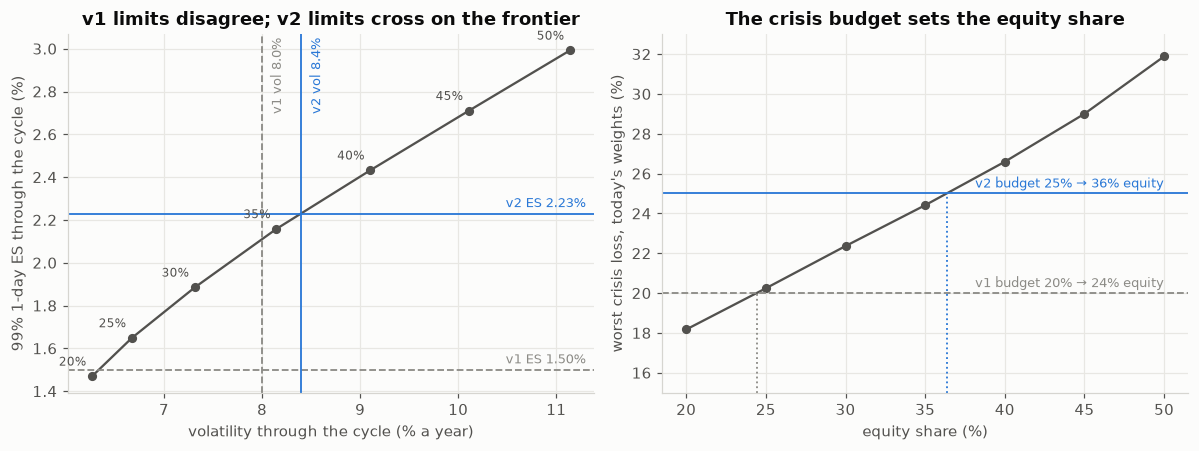

In [13]:
def at_es(l, a=0.99):
    """Acerbi-Tasche ES: average of the worst (1-a) share of losses, splitting a fractional observation."""
    x = np.sort(np.asarray(l))[::-1]; m = (1 - a) * len(x); k = int(np.floor(m + 1e-12))
    return float((x[:k].sum() + ((m - k) * x[k] if m - k > 1e-12 else 0.0)) / m)

dev = R.loc[:"2018-12-31"]
fr = pd.DataFrame({x: {"vol": float((dev @ wx).std() * np.sqrt(252)), "es99": at_es(-(dev @ wx)),
                       "crisis": CRISIS[x], "fwd": expected_return(wx)} for x, wx in WEIGHTS.items()}).T
xs = fr.index.to_numpy(float)
V1 = {"vol": 0.08, "crisis": 0.20, "es99": 0.015}
V2 = {"vol": 0.084, "crisis": 0.25, "es99": 0.0223}
cut = pd.DataFrame({ver: {k: float(np.interp(lim[k], fr[k], xs)) for k in ("vol", "crisis", "es99")}
                    for ver, lim in (("IPS v1", V1), ("IPS v2", V2))})
cut.index = ["volatility limit", "crisis-loss limit", "99% ES limit"]
display(cut.style.format("{:.0%}").set_caption("Equity share at which each limit cuts the frontier"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot(fr["vol"] * 100, fr["es99"] * 100, color=INK2, marker="o", markersize=5, linewidth=1.5)
for x, r in fr.iterrows():
    a1.annotate(f"{x:.0%}", (r.vol * 100, r.es99 * 100), textcoords="offset points", xytext=(-4, 7), fontsize=8, color=INK2, ha="right")
for lim, colr, style, name in ((V1, GREY, "--", "v1"), (V2, BLUE, "-", "v2")):
    a1.axvline(lim["vol"] * 100, color=colr, linestyle=style, linewidth=1.2)
    a1.axhline(lim["es99"] * 100, color=colr, linestyle=style, linewidth=1.2)
    a1.text(lim["vol"] * 100 + 0.08, 3.05, f"{name} vol {lim['vol']:.1%}", color=colr, fontsize=8.5, va="top", rotation=90)
    a1.text(11.3, lim["es99"] * 100 + 0.03, f"{name} ES {lim['es99']:.2%}", color=colr, fontsize=8.5, ha="right")
a1.set(xlabel="volatility through the cycle (% a year)", ylabel="99% 1-day ES through the cycle (%)",
       title="v1 limits disagree; v2 limits cross on the frontier")
a2.plot(xs * 100, fr["crisis"] * 100, color=INK2, marker="o", markersize=5, linewidth=1.5)
for lim, colr, style, name in ((V1, GREY, "--", "v1"), (V2, BLUE, "-", "v2")):
    x_at = float(np.interp(lim["crisis"], fr["crisis"], xs))
    a2.axhline(lim["crisis"] * 100, color=colr, linestyle=style, linewidth=1.2)
    a2.plot([x_at * 100] * 2, [15, lim["crisis"] * 100], color=colr, linestyle=":", linewidth=1.2)
    a2.text(50, lim["crisis"] * 100 + 0.3, f"{name} budget {lim['crisis']:.0%} → {x_at:.0%} equity", color=colr, fontsize=8.5, ha="right")
a2.set(xlabel="equity share (%)", ylabel="worst crisis loss, today's weights (%)", ylim=(15, 33),
       title="The crisis budget sets the equity share")
plt.tight_layout(); plt.show()

,35% portfolio,v1 limit,v2 limit,v1,v2
volatility,8.15%,8.00%,8.40%,FAIL,pass
worst crisis loss,24.41%,20.00%,25.00%,FAIL,pass
99% ES,2.16%,1.50%,2.23%,FAIL,pass


return objective (v2, D1): required 5.90%; forward expected return of the 35% portfolio 4.91%; gap 0.98% at end-2022 market levels


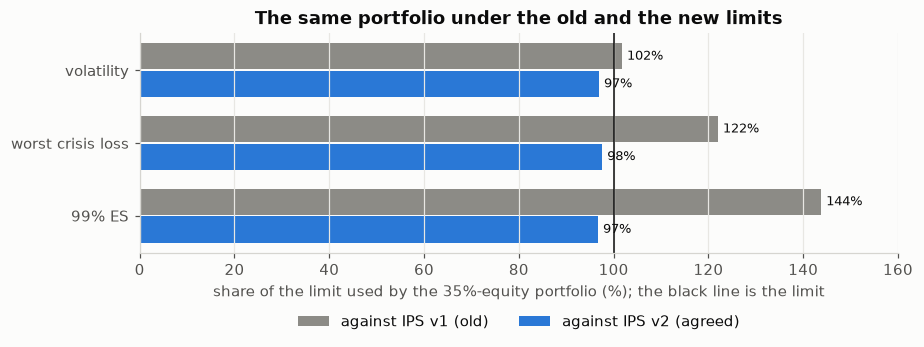

In [14]:
p35 = fr.loc[0.35]
use = pd.DataFrame({ver: {"volatility": p35.vol / lim["vol"], "worst crisis loss": p35.crisis / lim["crisis"],
                          "99% ES": p35.es99 / lim["es99"]} for ver, lim in (("IPS v1", V1), ("IPS v2", V2))})
tbl = pd.DataFrame({"35% portfolio": [p35.vol, p35.crisis, p35.es99], "v1 limit": [V1["vol"], V1["crisis"], V1["es99"]],
                    "v2 limit": [V2["vol"], V2["crisis"], V2["es99"]]}, index=use.index)
tbl["v1"] = np.where(use["IPS v1"] <= 1, "pass", "FAIL"); tbl["v2"] = np.where(use["IPS v2"] <= 1, "pass", "FAIL")
display(tbl.style.format({c: "{:.2%}" for c in ("35% portfolio", "v1 limit", "v2 limit")}))
print(f"return objective (v2, D1): required {required(0.03):.2%}; forward expected return of the 35% portfolio "
      f"{p35.fwd:.2%}; gap {required(0.03) - p35.fwd:.2%} at end-2022 market levels")

fig, ax = plt.subplots(figsize=(8.5, 3.4))
yy = np.arange(len(use))
for col, off, colr, lab in (("IPS v1", -0.19, GREY, "against IPS v1 (old)"), ("IPS v2", 0.19, BLUE, "against IPS v2 (agreed)")):
    ax.barh(yy + off, use[col] * 100, height=0.36, color=colr, label=lab)
    for i, v in enumerate(use[col]):
        ax.text(v * 100 + 1, i + off, f"{v:.0%}", va="center", fontsize=8.5, color=INK)
ax.axvline(100, color=INK, linewidth=1)
ax.set_yticks(yy, use.index); ax.invert_yaxis(); ax.set_xlim(0, 160)
ax.set(xlabel="share of the limit used by the 35%-equity portfolio (%); the black line is the limit",
       title="The same portfolio under the old and the new limits")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [15]:
# Production check: the pipeline (src/quantedge/decision/objective.py, written separately) must give these numbers.
import yaml
cfg_ips = yaml.safe_load((ROOT / "config.yaml").read_text())["ips"]
pipe_cal = pd.read_parquet(ART / "limit_calibration.parquet")
pipe_d = json.loads((ART / "limit_calibration.json").read_text())
pipe_req = json.loads((ART / "required_return.json").read_text())
cmp = pd.DataFrame({"notebook": fr[["vol", "es99", "crisis", "fwd"]].stack(),
                    "pipeline": pipe_cal.rename(columns={"vol_ann": "vol", "es99_1d": "es99", "worst_crisis_loss": "crisis",
                                                         "forward_return": "fwd"})[["vol", "es99", "crisis", "fwd"]].stack()})
cmp["gap (bp)"] = (cmp["pipeline"] - cmp["notebook"]) * 1e4
x25 = float(np.interp(0.25, fr["crisis"], xs))
own = {"equity share": x25, "vol limit": float(np.interp(x25, xs, fr["vol"])), "ES limit": float(np.interp(x25, xs, fr["es99"]))}
print(f"largest gap over {len(cmp)} numbers: {cmp['gap (bp)'].abs().max():.2f} bp")
print("D2 calibration  notebook:", {k: f"{v:.2%}" for k, v in own.items()})
print("                pipeline:", {"equity share": f"{pipe_d['equity_share']:.2%}", "vol limit": f"{pipe_d['vol_ann_max']:.2%}",
                                    "ES limit": f"{pipe_d['es99_1d_max']:.2%}"})
print(f"required return  notebook {required(0.03):.2%} | pipeline {pipe_req['required_return']:.2%}")
assert cmp["gap (bp)"].abs().max() < 0.6
assert abs(own["vol limit"] - pipe_d["vol_ann_max"]) < 5e-5 and abs(own["ES limit"] - pipe_d["es99_1d_max"]) < 5e-5
assert abs(required(0.03) - pipe_req["required_return"]) < 5e-5
assert (cfg_ips["limits"]["vol_ann_max"], cfg_ips["limits"]["es99_1d_max"], cfg_ips["limits"]["stress_drawdown_max"]) == (0.084, 0.0223, 0.25)
assert (cfg_ips["spending_rate"], cfg_ips["real_growth"]) == (0.03, 0.005)

largest gap over 28 numbers: 0.01 bp
D2 calibration  notebook: {'equity share': '36.35%', 'vol limit': '8.40%', 'ES limit': '2.23%'}
                pipeline: {'equity share': '36.35%', 'vol limit': '8.40%', 'ES limit': '2.23%'}
required return  notebook 5.90% | pipeline 5.90%


**Evidence:**
- **The v1 limits contradicted each other.** On the same frontier, the 8% volatility limit allows about 34% equity, the 20% crisis limit 24% and the 1.5% ES limit only 21%. Three limits gave three different answers, so whichever was tightest silently decided the portfolio, and the volatility limit was never the one that mattered. The cause: 99% ES is about 4× daily volatility for these portfolios, so 8% volatility implies about 2.1% ES, not 1.5%.
- **The v2 limits agree by construction.** All three are read off one client preference, the 25% crisis budget, so they cut the frontier at the same point (about 36% equity): volatility 8.40%, ES 2.23%.
- **Under v1, the recommended 35% portfolio broke all three risk limits** (102%, 122% and 144% of the limit). **Under v2 it passes all three** (97–98% of each). It sits just inside, by design: the budget sets the limit at 36% equity, and 35% is the round point below it. The causality runs from the client's preference to the limit to the portfolio, never backwards.
- **What now binds is return, not risk.** At end-2022 market levels the 35% portfolio's forward return (4.91%) is about 1 pp below the CPI + 3.5% objective (5.90%). This is the A2c finding: the verdict depends on the real yield at the decision date. (The pipeline's walk-forward weights, dated 2022-09-30, give 4.87% and a gap of 1.03%.)
- **Production check:** the pipeline's code, written separately (`src/quantedge/decision/objective.py`), reproduces every number here within 0.01 bp: the calibration, the forward returns and the 5.90% required return. `tests/test_objective.py` enforces the same.

**For the IPS change log (G26):** v1 → v2 on 2026-10-28; reason: incoherent limits replaced by limits derived from the D2 crisis budget; the recommendation under v1 = no compliant portfolio near 35% equity; under v2 = the 35% portfolio passes every risk limit, and the return objective decides the verdict.

---
# Part B · The verdict, by the locked rule (spec §5, inputs locked 2026-10-28)

**Dry run now; real run once after the freeze.** Everything below is driven by one constant, `DECISION_DATE`. The dry run uses 2022-12-31 (data up to the end of validation). After the tag `methodology-freeze-v1` exists, set it to the D7 decision date, 2026-10-26, rerun notebook 05 and then this notebook **once**, and report the result as it comes out. The guard in B1 refuses any later date before the tag exists. Data are those known the day before the decision (t − 1).

**The locked rule (spec §5):** score the minimum-variance frontier (20–50% equity; the caps force at least 20%) and recommend **the lowest-risk point that meets the required return and every risk limit** → **ACCEPT**. If none does, but the lowest-risk point meeting the required return would comply with the crisis budget loosened by at most 5 pp → **ADJUST THE RISK LIMIT** (amended limit for explicit committee approval). Otherwise → **REJECT**; a spending change is shown as advice, not as a verdict branch.

| Step | What | Gap closed |
|---|---|---|
| B1 | Locked inputs, guard, data to t − 1 | D7, test lock |
| B2 | Required return and market inputs at the decision date | G1 |
| B3 | Frontier scorecard and the limits recalibrated from D2 | G2, G3, G4, G22 |
| B4 | The verdict by the rule; break-even yield and ERP | spec §5 |
| B5 | Is the verdict robust? D4 assumption grid | G1 |
| B6 | Ten-year probabilities (context, not a criterion) | E6 |
| B7 | Recommendation, two alternatives in dollars, D8 sizing with a bootstrap check | G2, G23 |
| B8 | Model validity, the IPS change log and the base currency | spec §5 step 7, G26, G25 |

In [16]:
import subprocess
import yaml

DECISION_DATE = "2026-10-26"   # D7 decision date (real run, after the tag methodology-freeze-v1). Dry run: "2022-12-31"
LOCK = {"spending": 0.03, "growth": 0.005, "budget": 0.25, "adjust_pp": 0.05, "erp": 0.045, "spread": 0.005,
        "es_share_cap": 0.40}                                     # doc/decisions/inputs_lock.md (D1, D2, D4, D8)
ips_cfg = yaml.safe_load((ROOT / "config.yaml").read_text())["ips"]
assert (ips_cfg["spending_rate"], ips_cfg["real_growth"], ips_cfg["crisis_budget"], ips_cfg["forward"]["erp"],
        ips_cfg["forward"]["agg_spread"]) == (LOCK["spending"], LOCK["growth"], LOCK["budget"], LOCK["erp"], LOCK["spread"]), \
    "config.yaml and the input lock disagree"
D = pd.Timestamp(DECISION_DATE)
if D > pd.Timestamp(END):
    tag = subprocess.run(["git", "-C", str(ROOT), "tag", "-l", "methodology-freeze-v1"], capture_output=True, text=True).stdout.strip()
    assert tag, "2023+ data stay locked until the tag methodology-freeze-v1 exists"

rawB = pd.read_parquet(RAW / "prices.parquet"); rawB["date"] = pd.to_datetime(rawB["date"]); rawB = rawB[rawB["date"] < D]
wideB = lambda col: rawB.pivot(index="date", columns="ticker", values=col).sort_index()[TICKERS]
adjB, closeB, divB = wideB("adj_close"), wideB("close"), wideB("dividends").fillna(0)
RB = adjB.pct_change(fill_method=None).iloc[1:]

def fredB(name):
    s = pd.read_parquet(RAW / f"fred_{name}.parquet").iloc[:, -1]; s.index = pd.to_datetime(s.index)
    return s.loc[s.index < D].dropna()
print(f"decision date {D.date()}; data to {RB.index[-1].date()} ({len(RB):,} days); locked inputs: {LOCK}")

decision date 2026-10-26; data to 2026-10-23 (5,516 days); locked inputs: {'spending': 0.03, 'growth': 0.005, 'budget': 0.25, 'adjust_pp': 0.05, 'erp': 0.045, 'spread': 0.005, 'es_share_cap': 0.4}


## B1–B2 · Required return and market inputs at the decision date (G1)

Required return = (1 + 3%)(1 + 0.5%)(1 + π) − 1, with π the 10-year breakeven inflation (a market forecast, no CPI publication lag to handle). Forward returns: AGG = 10-year yield + 0.5%; equities = 10-year yield + β × 4.5%; gold = π; minus expense ratios, 15% withholding on equity dividends, trading costs and the volatility drag. **Check:** the nominal yield minus breakeven should match the TIPS real yield (DFII10) to a few basis points; if not, the inputs are stale or misaligned.

In [17]:
y10, piB, tips = (fredB(n).iloc[-1] / 100 for n in ("DGS10", "T10YIE", "DFII10"))
R_REQ = (1 + LOCK["spending"]) * (1 + LOCK["growth"]) * (1 + piB) - 1
estB = RB.iloc[-756:]
betaB = (estB.cov()["SPY"] / estB["SPY"].var()).reindex(TICKERS)
dyB = (divB.loc[RB.index[-1] - pd.Timedelta(days=365):].sum() / closeB.iloc[-1]).reindex(TICKERS)
S_nowB = LedoitWolf().fit(estB.to_numpy()).covariance_ * 252                  # optimiser window (756 days)
S_longB = LedoitWolf().fit(RB.to_numpy()).covariance_ * 252                    # long-run risk for the volatility drag

def fwdB(w, erp=LOCK["erp"], spread=LOCK["spread"], agg_wht=0.0, dy=0.0):
    """Net geometric forward return at the decision date; dy shifts the 10-year yield with inflation unchanged."""
    y = y10 + dy
    mu = pd.Series({t: (y + spread if t == "AGG" else piB if t == "GLD" else y + betaB[t] * erp) for t in TICKERS})
    wht = WHT.copy(); wht["AGG"] = agg_wht
    net = mu - EXPENSE.reindex(TICKERS) - dyB * wht - 0.0001
    return float(w @ net.to_numpy() - 0.5 * w @ S_longB @ w)

inputs = pd.Series({"10-year Treasury yield": y10, "10-year breakeven inflation (π)": piB, "10-year TIPS real yield": tips,
                    "nominal − breakeven": y10 - piB, "required return (CPI + 3.5%)": R_REQ})
display(inputs.to_frame("value").style.format("{:.2%}"))
display(pd.DataFrame({"beta to SPY (756 days)": betaB, "trailing dividend yield": dyB}).T.style.format("{:.2f}", subset=pd.IndexSlice["beta to SPY (756 days)", :])
        .format("{:.2%}", subset=pd.IndexSlice["trailing dividend yield", :]))
print(f"consistency: nominal − breakeven = {y10 - piB:.2%} vs TIPS {tips:.2%} (gap {abs(y10 - piB - tips) * 1e4:.0f} bp)")

,value
10-year Treasury yield,5.00%
10-year breakeven inflation (π),2.34%
10-year TIPS real yield,2.66%
nominal − breakeven,2.66%
required return (CPI + 3.5%),5.94%


ticker,SPY,EFA,EEM,AGG,GLD,XLE,XLK
beta to SPY (756 days),1.00,0.76,0.89,0.07,0.26,0.45,1.47
trailing dividend yield,1.00%,3.28%,1.80%,4.13%,0.00%,2.20%,0.46%


consistency: nominal − breakeven = 2.66% vs TIPS 2.66% (gap 0 bp)


## B3 · The frontier at the decision date, scored on every criterion (G2, G3, G4, G22)

For each equity share: minimum-variance weights (Ledoit-Wolf, 756 days, D3 caps); forward return against the requirement; volatility and 99% ES **through the cycle** (2004–2018, including the GFC); the worst historical crisis loss and the hypothetical scenario loss (notebook 05's stress betas and the agreed liquidity day), both with today's weights; the D2 loss = the worse of the two; income; the largest Euler ES share (D8). The volatility and ES limits are then **recalibrated mechanically** from the 25% budget at this date (D2), never typed in.

In [18]:
EVID = ROOT / "notebooks" / "evidence"
bh_file = EVID / f"05_stress_betas_{RB.index[-1].date()}.csv"
assert bh_file.exists(), f"run notebook 05 with data to {RB.index[-1].date()} first"
bh = pd.read_csv(bh_file, index_col=0)
assert bh["data_end"].iloc[0] == str(RB.index[-1].date()), "rerun notebook 05 on the same data first"
scen = pd.read_csv(EVID / "05_scenario.csv", index_col=0)["shock"]
LIQ = float(scen.pop("AGG liquidity day"))
B_h = bh.drop(columns="data_end").loc[TICKERS, scen.index]

def hyp_loss(w):
    return -(float(np.expm1(w @ (B_h @ scen).to_numpy())) + LIQ * w[TICKERS.index("AGG")])

def hist_loss(w, r=RB):
    return {k: path_loss(r.loc[(r.index > a) & (r.index <= b)] @ w) for k, (a, b) in CRISES.items()}

def es_shares(w, r=RB, a=0.99):
    l = -(r @ w); tail = l >= l.quantile(a)
    return pd.Series(w * (-r.loc[tail].mean().to_numpy()), index=TICKERS) / l[tail].mean()

devB = RB.loc[:"2018-12-31"]
net_inc = dyB * (1 - WHT)                                                      # AGG exempt (central)
WB = {x: min_var_at(x, S_nowB) for x in LEVELS}
rows = {}
for x, w in WB.items():
    h = hist_loss(w); sh = es_shares(w); ldev = -(devB @ w)
    rows[x] = {"forward return": fwdB(w), "vs required": fwdB(w) - R_REQ,
               "vol (through the cycle)": float(ldev.std() * np.sqrt(252)), "99% ES (through the cycle)": at_es(ldev),
               "worst historical crisis": max(h.values()), "which": max(h, key=h.get), "hypothetical + liquidity day": hyp_loss(w),
               "income yield (net)": float(w @ net_inc.to_numpy()), "largest ES share": sh.max(), "held by": sh.idxmax(),
               "caps binding": ", ".join(t for t, v in zip(TICKERS, w) if abs(v - CAPS[t]) < 1e-4) or "none"}
sc = pd.DataFrame(rows).T
sc["D2 loss"] = sc[["worst historical crisis", "hypothetical + liquidity day"]].astype(float).max(axis=1)
xs = np.array(LEVELS, float)
x_at = float(np.interp(LOCK["budget"], sc["D2 loss"].astype(float), xs))
LIMB = {"equity share at the budget": x_at,
        "volatility limit": float(np.interp(x_at, xs, sc["vol (through the cycle)"].astype(float))),
        "99% ES limit": float(np.interp(x_at, xs, sc["99% ES (through the cycle)"].astype(float)))}
sc["within every risk limit"] = ((sc["D2 loss"] <= LOCK["budget"] + 1e-9) & (sc["vol (through the cycle)"] <= LIMB["volatility limit"] + 1e-9)
                                 & (sc["99% ES (through the cycle)"] <= LIMB["99% ES limit"] + 1e-9))
sc["meets required return"] = sc["forward return"] >= R_REQ
sc.index = [f"{x:.0%}" for x in LEVELS]
pct_cols = ["forward return", "vs required", "vol (through the cycle)", "99% ES (through the cycle)", "worst historical crisis",
            "hypothetical + liquidity day", "D2 loss", "income yield (net)", "largest ES share"]
print("limits recalibrated from the 25% budget at this date:", {k: f"{v:.2%}" for k, v in LIMB.items()})
display(sc.style.format({c: "{:.2%}" for c in pct_cols}))
display(pd.DataFrame(WB, index=TICKERS).T.set_axis(sc.index).style.format("{:.1%}").set_caption("Weights at each equity share"))

limits recalibrated from the 25% budget at this date: {'equity share at the budget': '38.59%', 'volatility limit': '8.29%', '99% ES limit': '2.26%'}


,forward return,vs required,vol (through the cycle),99% ES (through the cycle),worst historical crisis,which,hypothetical + liquidity day,income yield (net),largest ES share,held by,caps binding,D2 loss,within every risk limit,meets required return
20%,5.19%,-0.74%,6.32%,1.52%,18.45%,GFC 2008,19.78%,2.96%,34.13%,XLE,"AGG, GLD",19.78%,True,False
25%,5.55%,-0.39%,6.46%,1.63%,19.98%,GFC 2008,20.16%,3.00%,35.95%,SPY,"AGG, XLE",20.16%,True,False
30%,5.81%,-0.13%,6.96%,1.84%,21.94%,GFC 2008,20.62%,3.13%,35.62%,SPY,"AGG, XLE",21.94%,True,False
35%,6.04%,0.11%,7.67%,2.08%,23.90%,GFC 2008,21.09%,3.27%,33.15%,SPY,"AGG, XLE",23.90%,True,True
40%,6.12%,0.18%,8.53%,2.33%,25.43%,GFC 2008,21.13%,3.16%,35.28%,SPY,XLE,25.43%,False,True
45%,6.19%,0.25%,9.43%,2.57%,27.04%,GFC 2008,21.18%,3.05%,36.15%,SPY,XLE,27.04%,False,True
50%,6.24%,0.31%,10.35%,2.83%,29.98%,GFC 2008,21.22%,2.95%,36.86%,SPY,XLE,29.98%,False,True


,SPY,EFA,EEM,AGG,GLD,XLE,XLK
20%,10.0%,0.0%,0.0%,65.0%,15.0%,10.0%,0.0%
25%,15.0%,0.0%,0.0%,65.0%,10.0%,10.0%,0.0%
30%,15.4%,4.6%,0.0%,65.0%,5.0%,10.0%,0.0%
35%,15.6%,9.4%,0.0%,65.0%,0.0%,10.0%,0.0%
40%,17.6%,12.4%,0.0%,60.0%,0.0%,10.0%,0.0%
45%,19.7%,15.3%,0.0%,55.0%,0.0%,10.0%,0.0%
50%,21.7%,18.3%,0.0%,50.0%,0.0%,10.0%,0.0%


## B4 · The verdict by the locked rule, and what would change it

The rule is applied mechanically to the table above. Then two break-even questions, which tell the committee how far the verdict is from flipping: by how much would the 10-year **real yield** have to be higher (inflation unchanged), and how large would the **equity premium** have to be?

VERDICT (2026-10-26): ACCEPT at 35% equity


  required 5.94%; best point inside every limit: 35% equity, forward 6.04% (gap -0.11%)
  margin: ACCEPT is lost if the real yield falls 0.15% (to 2.51% TIPS), or if the ERP is below 4.15% (locked 4.5%, range 3.5–5.5%)
  advice, not a verdict branch: the limits fund 3.10% spending with 0.5% real growth; 3% leaves $10,413 a year of headroom


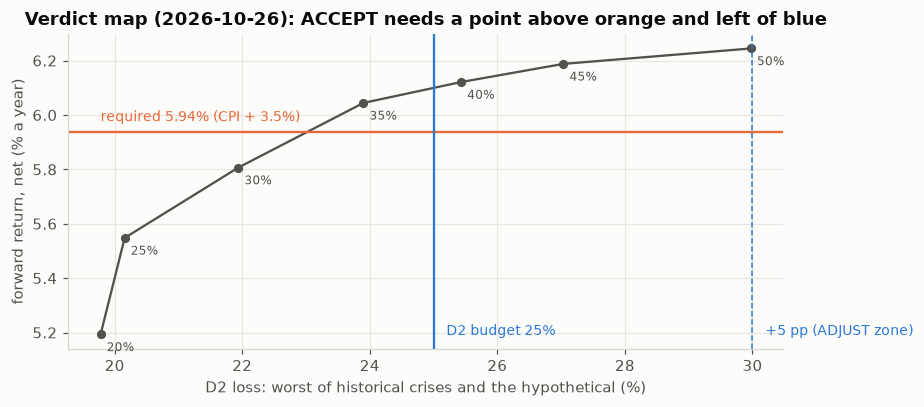

In [19]:
meets = sc["meets required return"]
ok = [x for x, k in zip(LEVELS, sc.index) if meets[k] and sc.loc[k, "within every risk limit"]]
near = [x for x, k in zip(LEVELS, sc.index) if meets[k] and sc.loc[k, "D2 loss"] <= LOCK["budget"] + LOCK["adjust_pp"] + 1e-9]
if ok:
    VERDICT, REC = "ACCEPT", min(ok)
elif near:
    VERDICT, REC = "ADJUST THE RISK LIMIT", min(near)
else:
    VERDICT, REC = "REJECT", None
feasible = [x for x, k in zip(LEVELS, sc.index) if sc.loc[k, "within every risk limit"]]
BEST = max(feasible, key=lambda x: fwdB(WB[x]))                           # highest forward return inside the limits
sust = (1 + fwdB(WB[BEST])) / ((1 + piB) * (1 + LOCK["growth"])) - 1        # spending it funds with 0.5% real growth

def accept_at(dy=0.0, erp=LOCK["erp"]):
    return any(fwdB(WB[x], erp=erp, dy=dy) >= R_REQ for x in feasible)
be_dy = next((d for d in np.arange(0, 0.03001, 0.0005) if accept_at(dy=d)), np.nan)
be_erp = next((e for e in np.arange(0, 0.15001, 0.0005) if accept_at(erp=e)), np.nan)
print(f"VERDICT ({D.date()}): {VERDICT}" + ("" if REC is None else f" at {REC:.0%} equity"))
print(f"  required {R_REQ:.2%}; best point inside every limit: {BEST:.0%} equity, forward {fwdB(WB[BEST]):.2%} "
      f"(gap {R_REQ - fwdB(WB[BEST]):.2%})")
if VERDICT == "ACCEPT":                                 # how far could the inputs move before ACCEPT is lost?
    lose_dy = next((d for d in np.arange(0, -0.03001, -0.0005) if not accept_at(dy=d)), np.nan)
    print(f"  margin: ACCEPT is lost if the real yield falls {-lose_dy:.2%} (to {tips + lose_dy:.2%} TIPS), "
          f"or if the ERP is below {be_erp:.2%} (locked 4.5%, range 3.5–5.5%)")
else:
    print(f"  break-even: real yield +{be_dy:.2%} (to {tips + be_dy:.2%} TIPS), or ERP {be_erp:.2%} (locked 4.5%, range 3.5–5.5%)")
gap_sp = (LOCK["spending"] - sust) * NAV
print(f"  advice, not a verdict branch: the limits fund {sust:.2%} spending with 0.5% real growth; "
      + (f"3% overspends by ${gap_sp:,.0f} a year" if gap_sp > 0 else f"3% leaves ${-gap_sp:,.0f} a year of headroom"))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(sc["D2 loss"].astype(float) * 100, sc["forward return"].astype(float) * 100, color=INK2, marker="o", markersize=5, linewidth=1.5)
for k in sc.index:
    ax.annotate(k, (sc.loc[k, "D2 loss"] * 100, sc.loc[k, "forward return"] * 100), textcoords="offset points", xytext=(4, -11), fontsize=8, color=INK2)
ax.axhline(R_REQ * 100, color=ORANGE, linewidth=1.5); ax.text(sc["D2 loss"].min() * 100, R_REQ * 100 + 0.04, f"required {R_REQ:.2%} (CPI + 3.5%)", color=ORANGE, fontsize=9)
ax.axvline(LOCK["budget"] * 100, color=BLUE, linewidth=1.5); ax.text(LOCK["budget"] * 100 + 0.2, ax.get_ylim()[0] + 0.05, "D2 budget 25%", color=BLUE, fontsize=9)
ax.axvline((LOCK["budget"] + LOCK["adjust_pp"]) * 100, color=BLUE, linestyle="--", linewidth=1)
ax.text((LOCK["budget"] + LOCK["adjust_pp"]) * 100 + 0.2, ax.get_ylim()[0] + 0.05, "+5 pp (ADJUST zone)", color=BLUE, fontsize=9)
ax.set(xlabel="D2 loss: worst of historical crises and the hypothetical (%)", ylabel="forward return, net (% a year)",
       title=f"Verdict map ({D.date()}): ACCEPT needs a point above orange and left of blue")
plt.tight_layout(); plt.show()

## B5 · Is the verdict robust to the assumptions? (D4 grid)

The ERP and the AGG spread are disclosed assumptions, and AGG's withholding status needs a tax adviser. The verdict is recomputed over the whole plausible range: ERP 3.5 / 4.5 / 5.5%, AGG spread 0.3 / 0.5 / 0.9%, AGG taxed or exempt (18 cases). A verdict that flips inside this grid would have to be reported as fragile.

In [20]:
def verdict_with(erp, spread, agg_wht):
    f = {x: fwdB(WB[x], erp, spread, agg_wht) for x in LEVELS}
    ok_ = [x for x in feasible if f[x] >= R_REQ]
    nr_ = [x for x, k in zip(LEVELS, sc.index) if f[x] >= R_REQ and sc.loc[k, "D2 loss"] <= LOCK["budget"] + LOCK["adjust_pp"] + 1e-9]
    return ("ACCEPT" if ok_ else "ADJUST" if nr_ else "REJECT"), max(f[x] for x in feasible) - R_REQ
grid = pd.DataFrame([{"ERP": e, "AGG spread": s, "AGG withholding": t, **dict(zip(["verdict", "best margin"], verdict_with(e, s, t)))}
                     for e in (0.035, 0.045, 0.055) for s in (0.003, 0.005, 0.009) for t in (0.0, 0.15)])
display(grid.pivot_table(index=["AGG withholding", "AGG spread"], columns="ERP", values="verdict", aggfunc="first"))
print("verdict counts over 18 cases:", grid["verdict"].value_counts().to_dict(),
      f"| best margin vs required: {grid['best margin'].min():+.2%} to {grid['best margin'].max():+.2%}")

ERP                          0.035   0.045   0.055
AGG withholding AGG spread                        
0.00            0.003       REJECT  ADJUST  ACCEPT
                0.005       REJECT  ACCEPT  ACCEPT
                0.009       ACCEPT  ACCEPT  ACCEPT
0.15            0.003       REJECT  REJECT  ADJUST
                0.005       REJECT  REJECT  ADJUST
                0.009       REJECT  ADJUST  ACCEPT

verdict counts over 18 cases: {'REJECT': 7, 'ACCEPT': 7, 'ADJUST': 4} | best margin vs required: -0.70% to +0.64%


## B6 · Ten years ahead: how likely is the objective, really? (context, not a verdict criterion)

The forward return is a central estimate; the committee also needs the odds. Ten years of monthly returns are resampled from 2005 to the decision date jointly with US CPI (stationary bootstrap, mean block 12 months), each portfolio re-centred to its forward estimate and inflation to the breakeven. Reported: the probability that the **10-year real return reaches 3.5% a year** (the objective), and the probability that real value **after spending** ends below 80%. Monte Carlo standard errors are shown, and the block length is varied because S6 showed the design drives the answer.

In [21]:
cpiB = fredB("CPIAUCSL")
monthlyB = (1 + RB.loc["2005-01-01":]).resample("ME").prod() - 1
inflB = cpiB.pct_change().reindex(monthlyB.index, method="ffill").to_numpy()
rngB = np.random.default_rng(20261029)
REAL_OBJ = (1 + LOCK["spending"]) * (1 + LOCK["growth"]) - 1

def ten_years(w, block=12, paths=5000, months=120, spend=LOCK["spending"]):
    r = (monthlyB @ w).to_numpy(); r = r - r.mean() + ((1 + fwdB(w)) ** (1 / 12) - 1)
    f = inflB - np.nanmean(inflB) + ((1 + piB) ** (1 / 12) - 1); f = np.nan_to_num(f, nan=(1 + piB) ** (1 / 12) - 1)
    n = len(r); idx = rngB.integers(0, n, paths)
    gross, price, value, hist = np.ones(paths), np.ones(paths), np.ones(paths), [np.ones(paths)] * 36
    for _ in range(months):
        gross *= 1 + r[idx]; price *= 1 + f[idx]; value = value * (1 + r[idx])
        hist = hist[1:] + [value]; value = value - spend / 12 * np.mean(hist, axis=0)
        jump = rngB.random(paths) < 1 / block
        idx = np.where(jump, rngB.integers(0, n, paths), (idx + 1) % n)
    real_ann = (gross / price) ** (1 / 10) - 1
    p_obj, p_loss = float(np.mean(real_ann >= REAL_OBJ)), float(np.mean(value / price < 0.8))
    return {"P(real return ≥ 3.5% a year)": p_obj, "s.e.": np.sqrt(p_obj * (1 - p_obj) / paths),
            "median real return a year": float(np.median(real_ann)), "P(real value after spending < 80%)": p_loss,
            "s.e. ": np.sqrt(p_loss * (1 - p_loss) / paths)}
POINT = REC if REC is not None else BEST
i_pt = LEVELS.index(POINT)
show = sorted({LEVELS[max(i_pt - 1, 0)], POINT, LEVELS[min(i_pt + 1, len(LEVELS) - 1)]})
sim = pd.DataFrame({f"{x:.0%} equity": ten_years(WB[x]) for x in show}).T
display(sim.style.format("{:.1%}"))
blk = pd.Series({f"block {b} months": ten_years(WB[POINT], block=b)["P(real return ≥ 3.5% a year)"] for b in (1, 12, 36)})
print(f"block-length sensitivity, {POINT:.0%} equity, P(objective met):", {k: f"{v:.1%}" for k, v in blk.items()})

,P(real return ≥ 3.5% a year),s.e.,median real return a year,P(real value after spending < 80%),s.e.
30% equity,43.4%,0.7%,3.2%,8.4%,0.4%
35% equity,49.8%,0.7%,3.5%,7.1%,0.4%
40% equity,49.6%,0.7%,3.5%,9.5%,0.4%


block-length sensitivity, 35% equity, P(objective met): {'block 1 months': '47.4%', 'block 12 months': '49.7%', 'block 36 months': '46.9%'}


## B7 · The recommendation, two alternatives in dollars, and the D8 sizing step (G2, G23)

The recommended point (or, if the verdict is REJECT, the best point inside every limit, as advice) is shown with one lower-risk and one higher-return alternative, all in dollars on USD 10M. Then the D8 rule: if one ETF carries more than 40% of the portfolio's 99% ES, its weight is moved to SPY until it no longer does. **Statistical check:** is the breach real or noise? A moving-block bootstrap (20-day blocks, 1,000 resamples) gives a confidence interval for the largest ES share before sizing.

In [22]:
def dollars(w):
    h = hist_loss(w)
    return {"expected return $ a year": fwdB(w) * NAV, "required $ a year": R_REQ * NAV, "shortfall $ a year": (R_REQ - fwdB(w)) * NAV,
            "worst historical crisis $": max(h.values()) * NAV, "hypothetical scenario $": hyp_loss(w) * NAV,
            "99% 1-day ES $ (through the cycle)": at_es(-(devB @ w)) * NAV, "income $ a year (net)": float(w @ net_inc.to_numpy()) * NAV}
tri = pd.DataFrame({("lower-risk" if x < POINT else "higher-return" if x > POINT else
                     ("RECOMMENDED" if REC is not None else "best inside the limits (advice)")) + f" · {x:.0%} equity": dollars(WB[x]) for x in show})
display(tri.style.format("${:,.0f}"))

# D8 sizing: move weight from the asset above the cap to SPY in 0.5 pp steps (SPY cap respected)
w0 = WB[POINT].copy(); w1 = w0.copy(); moves = 0
while es_shares(w1).max() > LOCK["es_share_cap"] and moves < 200:
    big = TICKERS.index(es_shares(w1).idxmax()); spy = TICKERS.index("SPY")
    step = min(0.005, w1[big], CAPS["SPY"] - w1[spy])
    if step <= 0: break
    w1[big] -= step; w1[spy] += step; moves += 1

def block_boot(w, reps=1000, block=20, seed=20261029):
    rg = np.random.default_rng(seed); X = RB.to_numpy(); n = len(X); out = np.empty(reps)
    for i in range(reps):
        starts = rg.integers(0, n - block, n // block + 1)
        Xb = X[(starts[:, None] + np.arange(block)).ravel()[:n]]
        out[i] = es_shares(w, pd.DataFrame(Xb, columns=TICKERS)).max()
    return np.quantile(out, [0.05, 0.95])
ci0 = block_boot(w0)
before_after = pd.DataFrame({"before D8": {**dict(zip(TICKERS, w0)), "largest ES share": es_shares(w0).max(), "forward return": fwdB(w0),
                                           "D2 loss": max(max(hist_loss(w0).values()), hyp_loss(w0)), "99% ES (through the cycle)": at_es(-(devB @ w0))},
                             "after D8": {**dict(zip(TICKERS, w1)), "largest ES share": es_shares(w1).max(), "forward return": fwdB(w1),
                                          "D2 loss": max(max(hist_loss(w1).values()), hyp_loss(w1)), "99% ES (through the cycle)": at_es(-(devB @ w1))}})
display(before_after.style.format("{:.2%}"))
print(f"largest ES share before sizing: {es_shares(w0).max():.1%} ({es_shares(w0).idxmax()}), "
      f"90% block-bootstrap interval {ci0[0]:.1%} to {ci0[1]:.1%} (cap {LOCK['es_share_cap']:.0%}); moved {moves * 0.5:.1f} pp to SPY")
print("after sizing, still inside every limit:", bool(max(max(hist_loss(w1).values()), hyp_loss(w1)) <= LOCK["budget"]
      and at_es(-(devB @ w1)) <= LIMB["99% ES limit"] + 1e-9 and float((devB @ w1).std() * np.sqrt(252)) <= LIMB["volatility limit"] + 1e-9))
W_FINAL = w1

,lower-risk · 30% equity,RECOMMENDED · 35% equity,higher-return · 40% equity
expected return $ a year,"$580,661","$604,435","$612,116"
required $ a year,"$593,725","$593,725","$593,725"
shortfall $ a year,"$13,064","$-10,710","$-18,391"
worst historical crisis $,"$2,193,809","$2,389,981","$2,543,146"
hypothetical scenario $,"$2,061,922","$2,108,553","$2,113,281"
99% 1-day ES $ (through the cycle),"$183,506","$208,295","$232,810"
income $ a year (net),"$313,127","$326,787","$316,089"


,before D8,after D8
SPY,15.57%,15.57%
EFA,9.43%,9.43%
EEM,0.00%,0.00%
AGG,65.00%,65.00%
GLD,0.00%,0.00%
XLE,10.00%,10.00%
XLK,0.00%,0.00%
largest ES share,33.15%,33.15%
forward return,6.04%,6.04%
D2 loss,23.90%,23.90%


largest ES share before sizing: 33.1% (SPY), 90% block-bootstrap interval 30.7% to 37.0% (cap 40%); moved 0.0 pp to SPY
after sizing, still inside every limit: True


## B8 · Model validity, the IPS change log and the base currency (spec §5 step 7, G26, G25)

- **Model validity (pre-committed):** the champion must pass Kupiec, Christoffersen and the Basel zone. On the dry run this is the 2019–2022 validation result; after the freeze it is the one-shot 2023–2026 test. If the champion fails Kupiec, the limits use the passing model with the higher current ES; if none passes, REJECT.
- **IPS change log:** the same rule under every IPS version, so the effect of each change is visible.
- **Base currency:** the mandate is in USD and the objective uses US CPI (an assumption); the scholarships are paid in rupees.

In [23]:
champ = json.loads((ART / "champion.json").read_text())["champion"]
if D <= pd.Timestamp(END):                              # dry run: the validation record
    ch = pd.read_parquet(ART / "backtest_selection_val_500.parquet").loc[champ]
    print(f"model validity (validation 2019–22, dry run): {champ}: {int(ch.exceptions)} exceptions vs {ch.expected:.1f}, "
          f"Kupiec p = {ch.kupiec_p:.2f}, conditional coverage p = {ch.cc_p:.2f} -> {'valid' if ch.passes else 'NOT valid'}")
else:                                                   # real run: the one-shot final test (spec §5 step 7)
    fr = json.loads((ART / "final_test_result.json").read_text())
    ch = pd.read_parquet(ART / "final_test_scores.parquet").loc[champ]
    print(f"model validity (final test {fr['test_start']} to {fr['test_end']}, {fr['days']} days): {champ}: "
          f"{int(ch.exceptions)} exceptions vs {0.01 * fr['days']:.1f}, Kupiec p = {ch.kupiec_p:.2f}, conditional coverage p = {ch.cc_p:.2f} "
          f"-> {'valid' if ch.passes else 'NOT valid'}; limits use {fr['limits_model']}")

def rule(spending, limits):
    """Spec §5 under an IPS version; `limits` = (crisis budget, volatility limit or None, ES limit or None)."""
    req = (1 + spending) * (1 + LOCK["growth"] if spending == LOCK["spending"] else 1) * (1 + piB) - 1
    budget, vmax, emax = limits
    inside = lambda k, b: (sc.loc[k, "D2 loss"] <= b + 1e-9 and (vmax is None or sc.loc[k, "vol (through the cycle)"] <= vmax + 1e-9)
                           and (emax is None or sc.loc[k, "99% ES (through the cycle)"] <= emax + 1e-9))
    okv = [k for k in sc.index if sc.loc[k, "forward return"] >= req and inside(k, budget)]
    if okv: return req, "ACCEPT", okv[0], ", ".join(k for k in sc.index if inside(k, budget)) or "none"
    nr = [k for k in sc.index if sc.loc[k, "forward return"] >= req and sc.loc[k, "D2 loss"] <= budget + LOCK["adjust_pp"] + 1e-9]
    return req, ("ADJUST" if nr else "REJECT"), (nr[0] if nr else "—"), ", ".join(k for k in sc.index if inside(k, budget)) or "none"
versions = {"v1 (Step 05): 4% spending; vol 8%, crisis 20%, ES 1.5%": (0.04, (0.20, 0.08, 0.015)),
            "v2 (agreed 2026-10-28): CPI + 3.5%; crisis 25%, limits from D2": (LOCK["spending"], (LOCK["budget"], LIMB["volatility limit"], LIMB["99% ES limit"]))}
log = pd.DataFrame({k: dict(zip(["required return", "verdict", "point", "points inside the limits"], rule(*v))) for k, v in versions.items()}).T
display(log.style.format({"required return": "{:.2%}"}))

fx = pd.read_parquet(RAW / "fx_LKR_X.parquet").iloc[:, 0]; fx = fx.loc[fx.index < D].dropna()
lk = pd.read_parquet(RAW / "ctx_FPCPITOTLZGLKA.parquet").iloc[:, 0]
port_usd = float(np.prod(1 + RB.loc["2005-01-01":] @ W_FINAL) ** (252 / len(RB.loc["2005-01-01":])) - 1)
fx_ann = (fx.iloc[-1] / fx.loc["2005-01-01":].iloc[0]) ** (365.25 / (fx.index[-1] - fx.loc["2005-01-01":].index[0]).days) - 1
print(f"base currency: LKR {fx.loc['2005-01-01':].iloc[0]:.1f} -> {fx.iloc[-1]:.1f} per USD ({fx_ann:+.1%} a year); "
      f"the recommended mix earned {port_usd:.1%} a year in USD and about {(1 + port_usd) * (1 + fx_ann) - 1:.1%} in rupees; "
      f"Sri Lanka CPI averaged {lk.loc['2005':str(D.year - 1)].mean():.1f}% a year (US CPI objective is an assumption)")

# Hand-off for the production check (tests/test_decision_date.py): the notebook's numbers, named by the data date
partb = {"decision_date": str(D.date()), "data_end": str(RB.index[-1].date()), "verdict": VERDICT, "recommended": REC, "advised": POINT,
         "required_return": R_REQ, "limits": LIMB, "weights": dict(zip(TICKERS, map(float, W_FINAL))),
         "frontier": {k: {c_: float(sc.loc[k, c_]) for c_ in ("forward return", "vol (through the cycle)", "99% ES (through the cycle)",
                                                                "worst historical crisis", "hypothetical + liquidity day", "D2 loss")} for k in sc.index},
         "erp_breakeven": float(be_erp), "robustness": grid["verdict"].value_counts().to_dict(),
         "ten_year_35": float(sim.loc[f"{POINT:.0%} equity", "P(real return ≥ 3.5% a year)"])}
(EVID / f"06_partB_{RB.index[-1].date()}.json").write_text(json.dumps(partb, indent=2, default=float))

model validity (final test 2023-01-01 to 2026-10-26, 955 days): GJR conditional EVT: 9 exceptions vs 9.6, Kupiec p = 0.86, conditional coverage p = 0.19 -> valid; limits use GJR conditional EVT


,required return,verdict,point,points inside the limits
"v1 (Step 05): 4% spending; vol 8%, crisis 20%, ES 1.5%",6.43%,REJECT,—,none
"v2 (agreed 2026-10-28): CPI + 3.5%; crisis 25%, limits from D2",5.94%,ACCEPT,35%,"20%, 25%, 30%, 35%"


base currency: LKR 103.3 -> 322.5 per USD (+5.4% a year); the recommended mix earned 5.8% a year in USD and about 11.5% in rupees; Sri Lanka CPI averaged 9.0% a year (US CPI objective is an assumption)


2935

## Part B findings · the real run at the decision date (26 October 2026, data to 23 October), run once after the freeze

**Verdict by the locked rule: ACCEPT the mandate as proposed, at 35% equity, with the objective CPI + 3.5%.**
- **The trigger we pre-registered was met.** The dry run said ACCEPT needs a 10-year TIPS yield of about 2.58% or more; on the decision date it was **2.66%** (nominal 5.00% − breakeven 2.34%; the two sources agree to 0 bp). Required return: **5.94%**.
- **The recommended portfolio:** SPY 15.6%, EFA 9.4%, AGG 65.0%, XLE 10.0% (minimum variance at 35% equity, D3 caps). Forward return **6.04%** net, **about USD 10,700 a year above** the requirement. Every risk limit passes: worst crisis loss 23.9% (GFC replay, weights held) and the scenario 21.1%, both inside the 25% budget; volatility 7.67% and 99% ES 2.08% through the cycle, inside the limits recalibrated at this date (8.29%, 2.26%; end-2022: 8.40%, 2.23%, so the calibration is stable). It is the lowest-risk point that meets the objective; 30% falls USD 13,000 a year short, and 40% breaks the crisis budget (25.4%).
- **It is a narrow ACCEPT, and we say so.** ACCEPT is lost if the real yield falls 0.15 pp (TIPS below 2.51%) or if the equity premium is below **4.15%** (locked 4.5%, plausible 3.5–5.5%). Over the 18 assumption cases the verdict is ACCEPT in 7, ADJUST in 4 and REJECT in 7 (margin −0.70% to +0.64%); taxing AGG's distributions turns most cases against it. The verdict is mechanical under the locked inputs, but the committee should hear that it rests on the 4.5% premium and AGG's tax treatment.
- **Odds over ten years (context):** about **50%** (s.e. 0.7 pp; 47–50% across block lengths) that the real return reaches 3.5% a year, median 3.5%; about a **7% chance** that real value after spending ends below 80% (26% at end-2022 levels). Higher yields made the plan safer, not just more likely to meet the objective.
- **Income now pays for the spending:** net distributions of about **USD 327,000 a year (3.27%)** cover the 3% spending rate in full.
- **D8 needs no resizing:** the largest tail-risk share is SPY's 33% (90% block-bootstrap interval 31–37%), below the 40% cap.
- **Model validity (final test, 955 days):** the champion had 9 breaches against 9.6 expected (Kupiec p = 0.86, conditional coverage p = 0.19): valid; the limits use it.
- **Caps now bind:** AGG (65%) and XLE (10%) are at their caps at 35% equity, unlike at end-2022. The recommendation therefore partly reflects the caps; this is disclosed, not re-optimised after the freeze.
- **IPS change log:** under v1 no portfolio fits the limits (REJECT); under v2 the 35% point is ACCEPT.
- **Base currency:** since 2005 the rupee fell from 103 to 323 per USD (+5.4% a year); the mix earned about 5.8% a year in USD and about 11.5% in rupees, against Sri Lanka CPI of about 9.0%.

**Dry run (end-2022, recorded before the freeze):** REJECT for return only (4.91% vs 5.90%), robust in 18 of 18 cases, with the pre-registered trigger "ACCEPT if TIPS ≥ about 2.58%". The real run is the same rule on the decision-date data; nothing was re-tuned between the two.